# Uber convertible notes: Tsiveriotis-Fernandes lattice valuation and validation
**Instruments:** Uber Technologies 0.875% Convertible Senior Notes due 2028 ($1,725M) and 0% Convertible Senior Notes due 2025 ($1,150M).
**Standards:** ASC 820 (Level 2 fair value disclosure), ASC 815-15 / 815-40 (embedded conversion option, capped calls), ASC 470-20 after ASU 2020-06, ASC 480.

**The test.** Uber discloses each note's fair value every quarter, rounded to $0.1bn. The model takes **no input from those fair values**: volatility is Uber's trailing realized volatility, and the credit spread is the ICE BofA index for Uber's rating at each date. If the model value falls inside the ±$0.05bn rounding band, it reproduces the reported number. Values are per $100 of principal unless stated.

## 1. Sources
| Item | Source |
|---|---|
| 2028 Notes terms: $1,725M, 0.875% (Jun/Dec), due 1-Dec-2028, 13.7848 shares per $1,000 ($72.54), soft call from 5-Dec-2026 at 130%, free conversion from 1-Sep-2028, cash for principal | Uber 8-K and pricing release (20-Nov-2023); 10-K FY2024, Note 8 |
| Capped calls: cap $95.81 (75% over $54.75), cost $141M ($122.25M on the base $1.5bn); recorded in APIC with no remeasurement | Pricing release; 10-K FY2024 |
| 2025 Notes terms: $1,150M, 0%, due 15-Dec-2025, 12.3701 shares per $1,000 ($80.84), soft call from 20-Dec-2023 at 130%; physical settlement eliminated Nov-2023 | Pricing release (8-Dec-2020); 10-Q Q1-2024, Note 5 |
| Disclosed fair values (Level 2, $bn): 2028 Notes 2.1 / 2.1 / 2.2 / 1.9 and 2025 Notes 1.3 / 1.2 / 1.3 / 1.2 at Mar / Jun / Sep / Dec 2024 | 10-Q Q1, Q2, Q3-2024; 10-K FY2024 |
| Treasury par curves at each 2024 quarter-end | US Treasury daily par yield curve, 2024 |
| 5-yr Treasury at issue: 4.49% (Nov-2023 average) | FRED GS5 |
| Credit spreads: ICE BofA BB and BBB option-adjusted spreads | FRED BAMLH0A1HYBB, BAMLC0A4CBBB |
| Ratings: S&P BB+ to BBB- (16-Aug-2024); Fitch BBB, Moody's Baa2 (Aug-2024); Uber 4.30% 2030 notes priced at T+75bp (4-Sep-2024) | Press coverage; Uber FWP (4-Sep-2024) |
| Uber month-end closing prices, May-2019 onward | digrin.com price history |

In [1]:
"""Uber convertible notes — Tsiveriotis-Fernandes (1998) binomial lattice valuation engine.

Instruments: 0.875% Convertible Senior Notes due 2028 and 0% Convertible Senior Notes due 2025.
All values per $1,000 principal unless stated; rates continuously compounded.
"""
from __future__ import annotations
from dataclasses import dataclass
from datetime import date
import math
import numpy as np
from scipy.stats import norm
from scipy.optimize import brentq

# ---------------------------------------------------------------- instruments
@dataclass
class Note:
    name: str
    principal_mm: float        # outstanding principal, $M
    coupon: float              # annual coupon rate
    freq: int                  # coupons per year
    maturity: date
    first_coupon: date | None  # first coupon date
    conv_rate: float           # shares per $1,000
    call_start: date           # provisional (soft) call allowed on/after
    call_trigger: float = 1.30 # stock >= trigger x conversion price
    face: float = 1000.0

    @property
    def conv_price(self):
        return self.face / self.conv_rate

    def coupon_dates(self):
        if self.coupon == 0 or self.first_coupon is None:
            return []
        out, d = [], self.first_coupon
        while d <= self.maturity:
            out.append(d)
            m = d.month + 12 // self.freq
            d = date(d.year + (m - 1) // 12, (m - 1) % 12 + 1, d.day)
        return out


NOTE_2028 = Note("2028 Notes (0.875%)", 1725.0, 0.00875, 2, date(2028, 12, 1), date(2024, 6, 1),
                 13.7848, date(2026, 12, 5))
NOTE_2025 = Note("2025 Notes (0%)", 1150.0, 0.0, 2, date(2025, 12, 15), None,
                 12.3701, date(2023, 12, 20))

# ---------------------------------------------------------------- market data
# Treasury par yields (%), US Treasury daily par yield curve. Tenors in years.
TENORS = [1/12, 2/12, 3/12, 4/12, 6/12, 1, 2, 3, 5, 7, 10, 20, 30]
CURVES = {
    date(2024, 3, 28): [5.49, 5.48, 5.46, 5.42, 5.38, 5.03, 4.59, 4.40, 4.21, 4.20, 4.20, 4.45, 4.34],
    date(2024, 6, 28): [5.47, 5.47, 5.48, 5.45, 5.33, 5.09, 4.71, 4.52, 4.33, 4.33, 4.36, 4.61, 4.51],
    date(2024, 9, 30): [4.93, 4.87, 4.73, 4.65, 4.38, 3.98, 3.66, 3.58, 3.58, 3.67, 3.81, 4.19, 4.14],
    date(2024, 12, 31): [4.40, 4.39, 4.37, 4.32, 4.24, 4.16, 4.25, 4.27, 4.38, 4.48, 4.58, 4.86, 4.78],
}
GS5_NOV2023 = 4.49   # FRED GS5, Nov-2023 monthly average (daily curve for 20-Nov-2023 not retrievable)

# ICE BofA option-adjusted spreads (%), FRED BAMLH0A1HYBB (BB) and BAMLC0A4CBBB (BBB)
OAS_BB = {date(2023, 11, 20): 2.51, date(2024, 3, 28): 1.87, date(2024, 6, 28): 1.84,
          date(2024, 9, 30): 1.89, date(2024, 12, 31): 1.86}
OAS_BBB = {date(2023, 11, 20): 1.46, date(2024, 3, 28): 1.15, date(2024, 6, 28): 1.17,
           date(2024, 9, 30): 1.16, date(2024, 12, 31): 1.02}
UPGRADE = date(2024, 8, 16)  # S&P BB+ -> BBB- (Fitch BBB 20-Aug, Moody's Baa2 27-Aug-2024)

# Uber month-end closes (digrin.com), used for spot and trailing realized volatility
MONTHLY_CLOSE = {
    "2019-05": 40.41, "2019-06": 46.38, "2019-07": 42.14, "2019-08": 32.57, "2019-09": 30.47, "2019-10": 31.50,
    "2019-11": 29.60, "2019-12": 29.74, "2020-01": 36.29, "2020-02": 33.87, "2020-03": 27.92, "2020-04": 30.27,
    "2020-05": 36.32, "2020-06": 31.08, "2020-07": 30.26, "2020-08": 33.63, "2020-09": 36.48, "2020-10": 33.41,
    "2020-11": 49.66, "2020-12": 51.00, "2021-01": 50.93, "2021-02": 51.75, "2021-03": 54.51, "2021-04": 54.77,
    "2021-05": 50.83, "2021-06": 50.12, "2021-07": 43.46, "2021-08": 39.14, "2021-09": 44.80, "2021-10": 43.82,
    "2021-11": 38.00, "2021-12": 41.93, "2022-01": 37.40, "2022-02": 36.03, "2022-03": 35.68, "2022-04": 31.48,
    "2022-05": 23.20, "2022-06": 20.46, "2022-07": 23.45, "2022-08": 28.76, "2022-09": 26.50, "2022-10": 26.57,
    "2022-11": 29.14, "2022-12": 24.73, "2023-01": 30.93, "2023-02": 33.26, "2023-03": 31.70, "2023-04": 31.05,
    "2023-05": 37.93, "2023-06": 43.17, "2023-07": 49.46, "2023-08": 47.23, "2023-09": 45.99, "2023-10": 43.28,
    "2023-11": 56.38, "2023-12": 61.57, "2024-01": 65.27, "2024-02": 79.50, "2024-03": 76.99, "2024-04": 66.27,
    "2024-05": 64.56, "2024-06": 72.68, "2024-07": 64.47, "2024-08": 73.13, "2024-09": 75.16, "2024-10": 72.05,
    "2024-11": 71.96, "2024-12": 60.32, "2025-01": 66.85, "2025-02": 76.01, "2025-03": 72.86, "2025-04": 81.01,
    "2025-05": 84.16, "2025-06": 93.30, "2025-07": 87.75, "2025-08": 93.75, "2025-09": 97.97, "2025-10": 96.50,
    "2025-11": 87.54, "2025-12": 81.71}

# Issue / capped-call data (pricing release 20-Nov-2023; 10-K FY2024)
ISSUE_DATE = date(2023, 11, 20)
ISSUE_SPOT = 54.75
CAP_PRICE = 95.81
CAPPED_CALL_COST_MM = 141.0      # for the full $1,725M (incl. option); $122.25M on the base $1,500M
NET_PROCEEDS_MM = 1700.0

# Disclosed fair values ($bn, Level 2, rounded to $0.1bn in the filings)
DISCLOSED = {  # date: (spot, {note: fv_bn})
    date(2024, 3, 28): (76.99, {"2028": 2.1, "2025": 1.3}),
    date(2024, 6, 28): (72.68, {"2028": 2.1, "2025": 1.2}),
    date(2024, 9, 30): (75.16, {"2028": 2.2, "2025": 1.3}),
    date(2024, 12, 31): (60.32, {"2028": 1.9, "2025": 1.2}),
}
NOTES = {"2028": NOTE_2028, "2025": NOTE_2025}


# ---------------------------------------------------------------- helpers
def yf(d0: date, d1: date) -> float:
    return (d1 - d0).days / 365.25


def cc(y_pct: float) -> float:
    """semi-annual bond-equivalent par yield (%) -> continuous rate"""
    return 2 * math.log(1 + y_pct / 200)


def rf(val_date: date, T: float) -> float:
    if val_date not in CURVES:
        return cc(GS5_NOV2023)
    return cc(float(np.interp(T, TENORS, CURVES[val_date])))


def spread(val_date: date, basis: str = "rating") -> float:
    """credit spread (decimal). 'rating': BB OAS before the S&P upgrade, BBB OAS after."""
    if basis == "BB":
        return OAS_BB[val_date] / 100
    if basis == "BBB":
        return OAS_BBB[val_date] / 100
    return (OAS_BB if val_date < UPGRADE else OAS_BBB)[val_date] / 100


def realized_vol(val_date: date, months: int = 36) -> float:
    keys = sorted(MONTHLY_CLOSE)
    end = f"{val_date.year}-{val_date.month:02d}"
    if val_date.day < 28:  # use last completed month
        m = val_date.month - 1 or 12
        y = val_date.year - (val_date.month == 1)
        end = f"{y}-{m:02d}"
    i = keys.index(end)
    px = np.array([MONTHLY_CLOSE[k] for k in keys[i - months:i + 1]])
    return float(np.std(np.diff(np.log(px)), ddof=1) * math.sqrt(12))


# ---------------------------------------------------------------- closed forms
def bs_call(S, K, T, r, sig, q=0.0):
    d1 = (math.log(S / K) + (r - q + 0.5 * sig ** 2) * T) / (sig * math.sqrt(T))
    return S * math.exp(-q * T) * norm.cdf(d1) - K * math.exp(-r * T) * norm.cdf(d1 - sig * math.sqrt(T))


def capped_call_value(S, K, cap, T, r, sig):
    return bs_call(S, K, T, r, sig) - bs_call(S, cap, T, r, sig)


def capped_call_implied_vol(r=None, T=None):
    shares = NOTE_2028.principal_mm * 1e6 / 1000 * NOTE_2028.conv_rate
    target = CAPPED_CALL_COST_MM * 1e6 / shares
    T = T or yf(ISSUE_DATE, NOTE_2028.maturity)
    r = cc(GS5_NOV2023) if r is None else r
    return brentq(lambda s: capped_call_value(ISSUE_SPOT, NOTE_2028.conv_price, CAP_PRICE, T, r, s) - target, 0.05, 1.5), target


def straight_bond(note: Note, val_date: date, r: float, s: float) -> float:
    """PV of remaining coupons + principal at r + s (cash flows on actual dates)."""
    pv = 0.0
    for d in note.coupon_dates():
        if d > val_date:
            pv += note.face * note.coupon / note.freq * math.exp(-(r + s) * yf(val_date, d))
    return pv + note.face * math.exp(-(r + s) * yf(val_date, note.maturity))


def tf_european(note: Note, val_date: date, S, sig, r, s) -> float:
    """TF value with conversion only at maturity and no call: CR*S*N(d1) + F e^{-(r+s)T} N(-d2) + PV coupons."""
    T = yf(val_date, note.maturity)
    K = note.conv_price
    d1 = (math.log(S / K) + (r + 0.5 * sig ** 2) * T) / (sig * math.sqrt(T))
    d2 = d1 - sig * math.sqrt(T)
    cpn = straight_bond(note, val_date, r, s) - note.face * math.exp(-(r + s) * T)
    return note.conv_rate * S * norm.cdf(d1) + note.face * math.exp(-(r + s) * T) * norm.cdf(-d2) + cpn


# ---------------------------------------------------------------- TF lattice
def tf_lattice(note: Note, val_date: date, S0, sig, r, s, N=500, call=True, early_conv=True,
               return_grid=False):
    """Tsiveriotis-Fernandes CRR lattice.
    V = total convertible value, B = cash-only component (discounted at r+s); V-B discounted at r.
    Coupons are paid at the first step on/after each coupon date. Soft call modelled as forced
    conversion at any node on/after call_start where S >= trigger x conversion price."""
    T = yf(val_date, note.maturity)
    dt = T / N
    u = math.exp(sig * math.sqrt(dt)); d = 1 / u
    p = (math.exp(r * dt) - d) / (u - d)
    dr, drs = math.exp(-r * dt), math.exp(-(r + s) * dt)
    F, CR = note.face, note.conv_rate
    cpn_amt = F * note.coupon / note.freq
    cpn = np.zeros(N + 1)
    for cd in note.coupon_dates():
        if cd > val_date:
            k = min(N, math.ceil(yf(val_date, cd) / dt - 1e-9))
            cpn[k] += cpn_amt
    t_call = yf(val_date, note.call_start)
    trig = note.call_trigger * note.conv_price
    j = np.arange(N + 1)
    S = S0 * u ** (N - 2 * j)
    conv = CR * S
    V = np.maximum(conv, F) + cpn[N]
    B = np.where(F >= conv, F, 0.0) + cpn[N]
    for k in range(N - 1, -1, -1):
        S = S0 * u ** (k - 2 * np.arange(k + 1))
        conv = CR * S
        E = p * (V[:-1] - B[:-1]) + (1 - p) * (V[1:] - B[1:])
        Bc = drs * (p * B[:-1] + (1 - p) * B[1:])
        Vc = dr * E + Bc
        if call and k * dt >= t_call - 1e-12:
            forced = S >= trig
            Vc = np.where(forced, conv, Vc); Bc = np.where(forced, 0.0, Bc)
        if early_conv:
            cv = conv > Vc
            Vc = np.where(cv, conv, Vc); Bc = np.where(cv, 0.0, Bc)
        V, B = Vc + cpn[k], Bc + cpn[k]
    return (float(V[0]), float(B[0])) if not return_grid else (float(V[0]), float(B[0]), u, p)


def value(note_key: str, val_date: date, S0=None, sig=None, s_basis="rating", N=500, **kw):
    note = NOTES[note_key]
    T = yf(val_date, note.maturity)
    S0 = S0 if S0 is not None else DISCLOSED[val_date][0]
    r = rf(val_date, T); s = spread(val_date, s_basis)
    V, B = tf_lattice(note, val_date, S0, sig, r, s, N=N, **kw)
    return dict(V=V, B=B, r=r, s=s, T=T, S=S0, parity=note.conv_rate * S0,
                floor=straight_bond(note, val_date, r, s))


def implied_vol(note_key, val_date, target_per_1000, s_basis="rating", N=400):
    f = lambda v: value(note_key, val_date, sig=v, s_basis=s_basis, N=N)["V"] - target_per_1000
    lo, hi = 0.01, 1.5
    if f(lo) > 0:
        return float("nan")  # value above target even at ~zero vol
    return brentq(f, lo, hi)


def implied_spread_at_par(sig, price=1000.0, N=500):
    T = yf(ISSUE_DATE, NOTE_2028.maturity); r = cc(GS5_NOV2023)
    f = lambda s: tf_lattice(NOTE_2028, ISSUE_DATE, ISSUE_SPOT, sig, r, s, N=N)[0] - price
    return brentq(f, -0.02, 0.30)


# ---------------------------------------------------------------- accounting exhibit
def legacy_ccf_split(sig, s_issue):
    """Pre-ASU 2020-06 cash conversion model (ASC 470-20): liability = straight-debt FV, equity = residual."""
    r = cc(GS5_NOV2023)
    liab = straight_bond(NOTE_2028, ISSUE_DATE, r, s_issue) / 1000 * NOTE_2028.principal_mm
    eq = NOTE_2028.principal_mm - liab
    # effective rate that accretes the liability to par with the 0.875% coupon (semi-annual, ~5 years)
    n = 10; c = 1000 * NOTE_2028.coupon / 2; pv = liab / NOTE_2028.principal_mm * 1000
    y = brentq(lambda y: sum(c / (1 + y / 2) ** i for i in range(1, n + 1)) + 1000 / (1 + y / 2) ** n - pv, 0.0, 0.5)
    return liab, eq, y



import pandas as pd, matplotlib.pyplot as plt, json
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

## 2. Instrument terms

In [2]:
terms = pd.DataFrame({k: {'Principal ($M)': n.principal_mm, 'Coupon': f'{n.coupon:.3%}', 'Maturity': n.maturity,
          'Conversion rate (per $1,000)': n.conv_rate, 'Conversion price ($)': round(n.conv_price, 2),
          'Soft call from': n.call_start, 'Call trigger ($)': round(n.call_trigger * n.conv_price, 2),
          'Underlying shares (M)': round(n.principal_mm * n.conv_rate / 1000, 3)} for k, n in NOTES.items()})
display(terms)

,2028,2025
Principal ($M),"1,725.000","1,150.000"
Coupon,0.875%,0.000%
Maturity,2028-12-01,2025-12-15
"Conversion rate (per $1,000)",13.785,12.370
Conversion price ($),72.540,80.840
Soft call from,2026-12-05,2023-12-20
Call trigger ($),94.310,105.090
Underlying shares (M),23.779,14.226


## 3. Market inputs at each valuation date

In [3]:
rows = []
for dte, (S, fv) in DISCLOSED.items():
    for k, n in NOTES.items():
        T = yf(dte, n.maturity)
        rows.append([dte, k, S, T, rf(dte, T), spread(dte), 'BB' if dte < UPGRADE else 'BBB', realized_vol(dte), fv[k]])
inp = pd.DataFrame(rows, columns=['Date', 'Note', 'Spot', 'T (yrs)', 'r (cont.)', 'Spread', 'Rating index', 'σ (36m realized)', 'Disclosed FV ($bn)'])
display(inp)

,Date,Note,Spot,T (yrs),r (cont.),Spread,Rating index,σ (36m realized),Disclosed FV ($bn)
0,2024-03-28,2028,76.990,4.679,0.042,0.019,BB,0.448,2.100
1,2024-03-28,2025,76.990,1.717,0.047,0.019,BB,0.448,1.300
2,2024-06-28,2028,72.680,4.427,0.043,0.018,BB,0.460,2.100
3,2024-06-28,2025,72.680,1.465,0.049,0.018,BB,0.460,1.200
4,2024-09-30,2028,75.160,4.170,0.035,0.012,BBB,0.451,2.200
5,2024-09-30,2025,75.160,1.207,0.039,0.012,BBB,0.451,1.300
6,2024-12-31,2028,60.320,3.918,0.043,0.010,BBB,0.454,1.900
7,2024-12-31,2025,60.320,0.956,0.041,0.010,BBB,0.454,1.200


* **Risk-free rate:** the Treasury par yield interpolated at each note's remaining term, converted to a continuous rate.
* **Credit spread:** the BB index while Uber was rated BB+, and the BBB index after S&P's upgrade on 16-Aug-2024.
* **Volatility:** the standard deviation of 36 monthly log returns ending at the valuation month, annualized. It sits at 45–46% throughout 2024.

None of these inputs is taken from the disclosed fair values.

## 4. Lattice verification
**Tsiveriotis-Fernandes (1998)** splits the convertible into two parts:
* the **cash-only component** B (coupons, principal, call cash), discounted at r + s;
* the **equity component** V − B, discounted at r.

At each node, conversion sets B = 0, and the soft call forces conversion once S ≥ 130% of the conversion price after the call date. With no call and no early conversion, the lattice must converge to the closed form CR·S·N(d₁) + F·e^{−(r+s)T}·N(−d₂) + PV(coupons).

,European lattice,Closed form,Error,Full lattice (call + early conv.)
N,,,,
25,"1,255.931","1,253.515",2.416,"1,231.720"
50,"1,255.279","1,253.515",1.763,"1,223.384"
60,"1,255.268","1,253.515",1.752,"1,233.447"
100,"1,255.122","1,253.515",1.607,"1,226.145"
200,"1,254.820","1,253.515",1.305,"1,223.853"
400,"1,254.515","1,253.515",1.000,"1,224.810"
800,"1,254.253","1,253.515",0.737,"1,223.095"
1600,"1,254.046","1,253.515",0.531,"1,222.198"


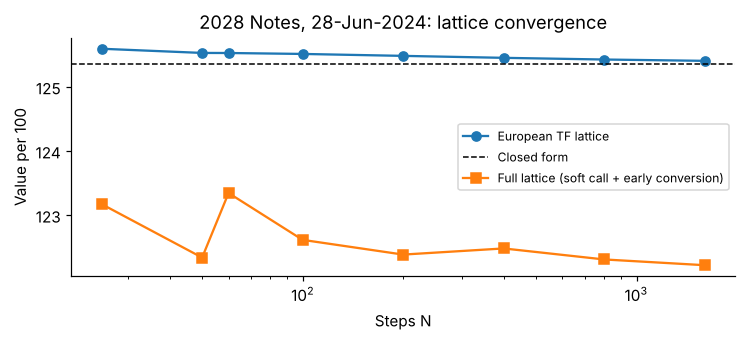

In [4]:
dte = date(2024, 6, 28); S = 72.68; sig = realized_vol(dte)
T = yf(dte, NOTE_2028.maturity); r = rf(dte, T); s = spread(dte)
cf = tf_european(NOTE_2028, dte, S, sig, r, s)
Ns = [25, 50, 60, 100, 200, 400, 800, 1600]
eu = [tf_lattice(NOTE_2028, dte, S, sig, r, s, N=n, call=False, early_conv=False)[0] for n in Ns]
am = [tf_lattice(NOTE_2028, dte, S, sig, r, s, N=n)[0] for n in Ns]
conv = pd.DataFrame({'N': Ns, 'European lattice': eu, 'Closed form': cf, 'Error': np.array(eu) - cf, 'Full lattice (call + early conv.)': am})
display(conv.set_index('N'))
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(Ns, np.array(eu) / 10, 'o-', label='European TF lattice'); ax.axhline(cf / 10, color='k', ls='--', lw=1, label='Closed form')
ax.plot(Ns, np.array(am) / 10, 's-', label='Full lattice (soft call + early conversion)')
ax.set_xscale('log'); ax.set_xlabel('Steps N'); ax.set_ylabel('Value per 100'); ax.set_title('2028 Notes, 28-Jun-2024: lattice convergence'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

The European lattice converges to the closed form; the gap is about 0.05 per 100 at 1,600 steps. Adding the soft call and early-conversion rights lowers the value by about 3 points per 100, because the call is the issuer's option and caps upside above $94.31. Uber pays no dividend, so voluntary early conversion is never optimal. The value difference therefore comes from the soft call. With the soft-call barrier the lattice oscillates slightly with N. The Excel model uses 100 steps, and §10 reports the resulting discretization error.

## 5. Issue date (20-Nov-2023): two market prices observed on day one

Capped call paid: $5.930 per share  ($141M / 23.779M shares)
Maximum flat-vol Black-Scholes value: $4.901 at σ = 28%  ->  no single volatility reproduces the price
With σ(72.54) = 46.3% (36m realized), the price implies σ(95.81) = 43.2%: a skew of 3.1 vol points over a 32% wider strike


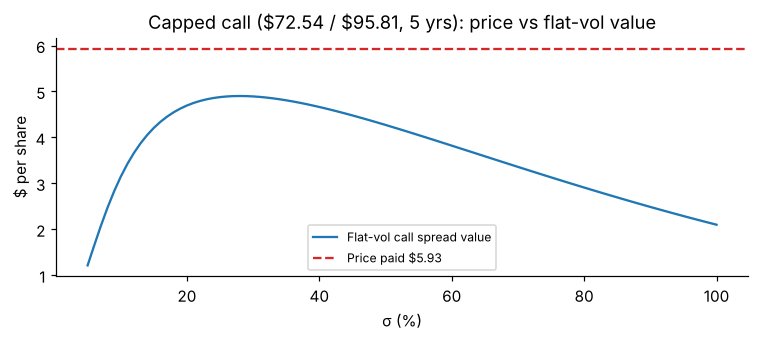

In [5]:
sig_iss = realized_vol(ISSUE_DATE); T0 = yf(ISSUE_DATE, NOTE_2028.maturity); r0 = cc(GS5_NOV2023); K = NOTE_2028.conv_price
shares = NOTE_2028.principal_mm * NOTE_2028.conv_rate / 1000
cc_per_share = CAPPED_CALL_COST_MM / shares
vols = np.linspace(0.05, 1.0, 96)
ccv = [capped_call_value(ISSUE_SPOT, K, CAP_PRICE, T0, r0, v) for v in vols]
print(f"Capped call paid: ${cc_per_share:.3f} per share  (${CAPPED_CALL_COST_MM:.0f}M / {shares:.3f}M shares)")
print(f"Maximum flat-vol Black-Scholes value: ${max(ccv):.3f} at σ = {vols[int(np.argmax(ccv))]:.0%}  ->  no single volatility reproduces the price")
skew = brentq(lambda d: bs_call(ISSUE_SPOT, K, T0, r0, sig_iss) - bs_call(ISSUE_SPOT, CAP_PRICE, T0, r0, sig_iss - d) - cc_per_share, 0, 0.3)
print(f"With σ({K:.2f}) = {sig_iss:.1%} (36m realized), the price implies σ({CAP_PRICE}) = {sig_iss-skew:.1%}: a skew of {skew*100:.1f} vol points over a 32% wider strike")
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(vols * 100, ccv, label='Flat-vol call spread value'); ax.axhline(cc_per_share, color='C3', ls='--', label=f'Price paid \\${cc_per_share:.2f}')
ax.set_xlabel('σ (%)'); ax.set_ylabel('\\$ per share'); ax.set_title('Capped call (\\$72.54 / \\$95.81, 5 yrs): price vs flat-vol value'); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Capped call.** The call spread costs more than its maximum possible flat-volatility value. That is not an error: dealers price the cap strike off a lower implied volatility than the lower strike (equity skew), and they earn a margin. With 46% at the conversion price, a skew of about 3 volatility points to the cap reproduces the $141M exactly. Two conclusions follow:
* Flat-vol Black-Scholes **understates** call spreads of this kind. For an ASC 815-40 fair value of a warrant or capped call, the vol surface matters.
* Realized volatility of about 46% is consistent with what the dealers charged.

In [6]:
iss = pd.DataFrame([[v, sp, tf_lattice(NOTE_2028, ISSUE_DATE, ISSUE_SPOT, v, r0, sp, N=800)[0] / 10] for v in (0.35, 0.40, sig_iss) for sp in (OAS_BBB[ISSUE_DATE] / 100, OAS_BB[ISSUE_DATE] / 100)],
                   columns=['σ', 'Spread', 'Model value at issue (per 100)'])
display(iss)
v_iss = tf_lattice(NOTE_2028, ISSUE_DATE, ISSUE_SPOT, sig_iss, r0, spread(ISSUE_DATE), N=800)[0] / 10
iv_par = brentq(lambda v: tf_lattice(NOTE_2028, ISSUE_DATE, ISSUE_SPOT, v, r0, spread(ISSUE_DATE), N=800)[0] - 1000, 0.05, 1.0)
is_par = implied_spread_at_par(sig_iss, N=800)
print(f"Base case at issue (σ {sig_iss:.1%}, BB spread {spread(ISSUE_DATE):.2%}): {v_iss:.2f} per 100 vs issue price 100.00 -> new-issue discount {v_iss-100:.2f} points")
print(f"Implied σ at par: {iv_par:.1%};  implied credit spread at par with σ {sig_iss:.1%}: {is_par:.2%}")

,σ,Spread,Model value at issue (per 100)
0,0.350,0.015,100.083
1,0.350,0.025,97.664
2,0.400,0.015,102.869
3,0.400,0.025,100.439
4,0.463,0.015,106.000
5,0.463,0.025,103.583


Base case at issue (σ 46.3%, BB spread 2.51%): 103.58 per 100 vs issue price 100.00 -> new-issue discount 3.58 points
Implied σ at par: 39.2%;  implied credit spread at par with σ 46.3%: 4.17%


**Issue price.** Investors bought at par a note the model values at about 103.6. This new-issue discount is well documented in the convertible market and is how convertible-arbitrage funds are paid to take down a deal and hedge it. The implied volatility at par is about 39%, and the implied spread at par (at 46% volatility) is about 4.2% against a BB index of 2.5%. Day-one fair value under ASC 820 is the transaction price unless evidence shows otherwise (ASC 820-10-30-3). After issue, the notes trade and the quarterly test below applies.

## 6. The test: model vs disclosed fair value at four quarter-ends (no inputs fitted)

In [7]:
res = []
for dte, (S, fv) in DISCLOSED.items():
    for k, n in NOTES.items():
        v = value(k, dte, sig=realized_vol(dte), N=1000)
        rep = fv[k] * 1e6 / n.principal_mm
        lo, hi = (fv[k] - 0.05) * 1e6 / n.principal_mm, (fv[k] + 0.05) * 1e6 / n.principal_mm
        res.append(dict(Date=dte, Note=k, Spot=S, Parity=v['parity'] / 10, Floor=v['floor'] / 10, Model=v['V'] / 10,
                        Reported=rep / 10, Low=lo / 10, High=hi / 10, Model_bn=v['V'] * n.principal_mm / 1e6,
                        Reported_bn=fv[k], In_band=lo <= v['V'] <= hi, Err_vs_mid=v['V'] / rep - 1))
res = pd.DataFrame(res); display(res)
print(f"Inside the rounding band: {res.In_band.sum()} of {len(res)};  rounds to the reported $bn figure: {(res.Model_bn.round(1) == res.Reported_bn).sum()} of {len(res)}")
print(f"Mean absolute error vs band midpoint: {res.Err_vs_mid.abs().mean():.1%}")

,Date,Note,Spot,Parity,Floor,Model,Reported,Low,High,Model_bn,Reported_bn,In_band,Err_vs_mid
0,2024-03-28,2028,76.990,106.129,79.079,127.081,121.739,118.841,124.638,2.192,2.100,False,0.044
1,2024-03-28,2025,76.990,95.237,89.396,110.188,113.043,108.696,117.391,1.267,1.300,True,-0.025
2,2024-06-28,2028,72.680,100.188,79.474,122.309,121.739,118.841,124.638,2.110,2.100,True,0.005
3,2024-06-28,2025,72.680,89.906,90.660,107.472,104.348,100.000,108.696,1.236,1.200,True,0.030
4,2024-09-30,2028,75.160,103.607,85.736,126.525,127.536,124.638,130.435,2.183,2.200,True,-0.008
5,2024-09-30,2025,75.160,92.974,94.101,109.811,113.043,108.696,117.391,1.263,1.300,True,-0.029
6,2024-12-31,2028,60.320,83.150,84.393,110.578,110.145,107.246,113.043,1.907,1.900,True,0.004
7,2024-12-31,2025,60.320,74.616,95.203,101.540,104.348,100.000,108.696,1.168,1.200,True,-0.027


Inside the rounding band: 7 of 8;  rounds to the reported $bn figure: 7 of 8
Mean absolute error vs band midpoint: 2.1%


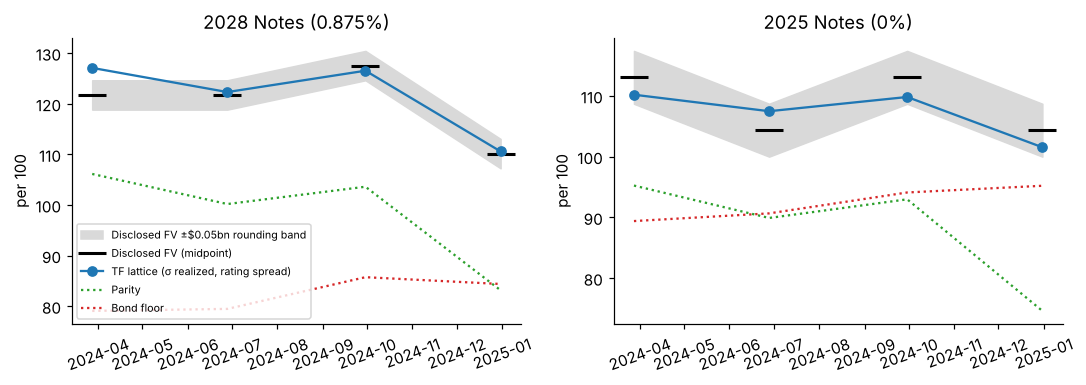

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=False)
for ax, k in zip(axes, ['2028', '2025']):
    d = res[res.Note == k]; x = pd.to_datetime(d.Date)
    ax.fill_between(x, d.Low, d.High, color='0.85', label='Disclosed FV ±\\$0.05bn rounding band')
    ax.plot(x, d.Reported, 'k_', ms=18, mew=2, label='Disclosed FV (midpoint)')
    ax.plot(x, d.Model, 'o-', color='C0', label='TF lattice (σ realized, rating spread)')
    ax.plot(x, d.Parity, ':', color='C2', label='Parity'); ax.plot(x, d.Floor, ':', color='C3', label='Bond floor')
    ax.set_title(f'{NOTES[k].name}'); ax.set_ylabel('per 100'); ax.tick_params(axis='x', rotation=20)
axes[0].legend(fontsize=7, loc='lower left'); plt.tight_layout(); plt.show()

**Result.** Seven of eight model values fall inside the rounding band, with nothing fitted. The one miss is the 2028 Notes on 28-Mar-2024: the model gives $2.19bn against a reported $2.1bn. In February 2024 the stock rose 22% on Uber's first full-year operating profit and buyback announcement. The backsolve in §7 shows that the reported value implies about 35% volatility, well below the 45% trailing figure, consistent with forward-looking volatility falling after the earnings rally.

## 7. Implied volatility from each disclosed fair value

,Date,Note,IV_mid,IV_low,IV_high,RV36
0,2024-03-28,2028,0.349,0.298,0.402,0.448
1,2024-03-28,2025,0.607,0.380,1.215,0.448
2,2024-06-28,2028,0.447,0.391,0.507,0.460
3,2024-06-28,2025,0.343,0.225,0.495,0.460
4,2024-09-30,2028,0.469,0.411,0.519,0.451
5,2024-09-30,2025,0.628,0.402,1.231,0.451
6,2024-12-31,2028,0.439,0.382,0.498,0.454
7,2024-12-31,2025,0.585,0.386,0.892,0.454


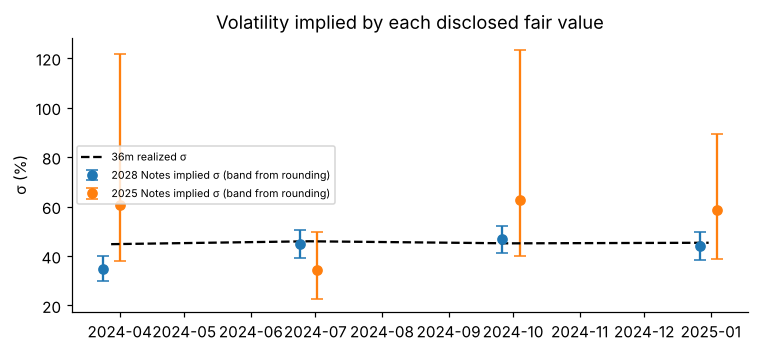

In [9]:
iv = []
for dte, (S, fv) in DISCLOSED.items():
    for k, n in NOTES.items():
        f = lambda bn: implied_vol(k, dte, bn * 1e6 / n.principal_mm, N=400)
        iv.append(dict(Date=dte, Note=k, IV_mid=f(fv[k]), IV_low=f(fv[k] - 0.05), IV_high=f(fv[k] + 0.05), RV36=realized_vol(dte)))
iv = pd.DataFrame(iv); display(iv)
fig, ax = plt.subplots(figsize=(7, 3.3))
for k, c in [('2028', 'C0'), ('2025', 'C1')]:
    d = iv[iv.Note == k]; x = pd.to_datetime(d.Date) + pd.Timedelta(days=4 if k == '2025' else -4)
    ax.errorbar(x, d.IV_mid * 100, yerr=[(d.IV_mid - d.IV_low.fillna(0)) * 100, (d.IV_high - d.IV_mid) * 100], fmt='o', color=c, capsize=4, label=f'{k} Notes implied σ (band from rounding)')
ax.plot(pd.to_datetime(iv.Date.unique()), iv.groupby('Date').RV36.first() * 100, 'k--', label='36m realized σ')
ax.set_ylabel('σ (%)'); ax.set_title('Volatility implied by each disclosed fair value'); ax.legend(fontsize=7); plt.tight_layout(); plt.show()

* The 2028 Notes pin volatility down tightly: about ±5 vol points from rounding, because the longer option carries a lot of vega. Their implied σ runs 35–47%, close to realized volatility in every quarter after March 2024.
* The 2025 Notes are short-dated and mostly bond-like, so the $0.1bn rounding spans 30+ vol points. They carry little information about σ but confirm the bond-floor side.
* **Calibrated alternative:** a single σ fitted to the four 2028-note values is about 43%, within 3 points of the realized figure. The base case does not need it.

## 8. What drives the value: the convertible profile at 31-Dec-2024

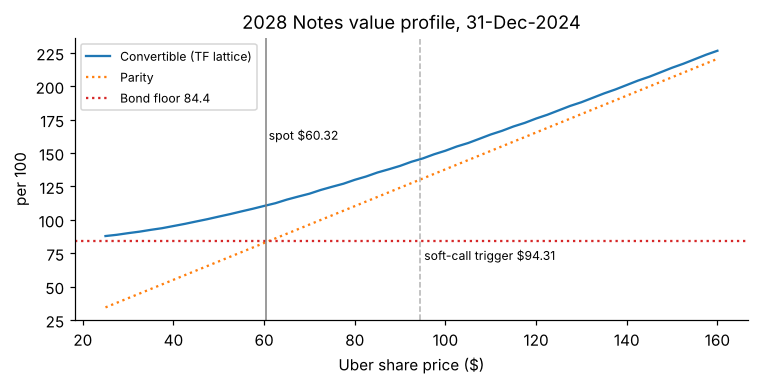

Value 110.84 = bond floor 84.39 + conversion option 26.45;  premium to parity 33.3%
Delta 0.47 (hedge ratio, shares per share-equivalent); vega 0.159 per vol point; CS01 -0.0184 per bp (per 100)


In [10]:
dte = date(2024, 12, 31); sig = realized_vol(dte); n = NOTE_2028; T = yf(dte, n.maturity); r = rf(dte, T); s = spread(dte)
Sg = np.linspace(25, 160, 55)
cb = [tf_lattice(n, dte, x, sig, r, s, N=300)[0] / 10 for x in Sg]
floor = straight_bond(n, dte, r, s) / 10
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(Sg, cb, label='Convertible (TF lattice)'); ax.plot(Sg, n.conv_rate * Sg / 10, ':', label='Parity'); ax.axhline(floor, color='C3', ls=':', label=f'Bond floor {floor:.1f}')
ax.axvline(60.32, color='0.5', lw=1); ax.text(61, 160, 'spot \\$60.32', fontsize=8); ax.axvline(n.conv_price * 1.3, color='0.7', ls='--', lw=1); ax.text(n.conv_price * 1.3 + 1, 70, 'soft-call trigger \\$94.31', fontsize=8)
ax.set_xlabel('Uber share price (\\$)'); ax.set_ylabel('per 100'); ax.set_title('2028 Notes value profile, 31-Dec-2024'); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
h = 0.5
up, dn = tf_lattice(n, dte, 60.32 + h, sig, r, s, N=600)[0], tf_lattice(n, dte, 60.32 - h, sig, r, s, N=600)[0]
mid = tf_lattice(n, dte, 60.32, sig, r, s, N=600)[0]
delta = (up - dn) / (2 * h) / n.conv_rate
vega = (tf_lattice(n, dte, 60.32, sig + 0.01, r, s, N=600)[0] - mid) / 10
cs01 = (tf_lattice(n, dte, 60.32, sig, r, s + 0.0001, N=600)[0] - mid) / 10
print(f"Value {mid/10:.2f} = bond floor {floor:.2f} + conversion option {mid/10-floor:.2f};  premium to parity {mid/(n.conv_rate*60.32)-1:.1%}")
print(f"Delta {delta:.2f} (hedge ratio, shares per share-equivalent); vega {vega:.3f} per vol point; CS01 {cs01:.4f} per bp (per 100)")

At year-end 2024 the 2028 Notes were a **balanced** convertible: 17% out of the money, with delta around 0.5. Their value splits into about 84 points of bond floor and 26 points of conversion option. Both credit and volatility therefore matter, and this is why the valuation needs a lattice rather than a bond-plus-call shortcut. The soft call caps the curve: above $94.31 after December 2026, the issuer forces conversion and the value collapses onto parity.

## 9. Sensitivities

In [11]:
dte = date(2024, 12, 31); n = '2028'
sg = [0.35, 0.40, 0.45, 0.50]; sp = [0.0050, 0.0075, 0.0102, 0.0150, 0.0200]
grid = pd.DataFrame([[tf_lattice(NOTES[n], dte, 60.32, a, rf(dte, yf(dte, NOTES[n].maturity)), b, N=400)[0] * NOTES[n].principal_mm / 1e6 for b in sp] for a in sg],
                    index=[f'σ {a:.0%}' for a in sg], columns=[f's {b*1e4:.0f}bp' for b in sp])
print('2028 Notes fair value ($bn), 31-Dec-2024 (reported 1.9, band 1.85–1.95):'); display(grid)
# Uber-specific credit: 2030 senior notes priced at T+75bp on 4-Sep-2024 vs BBB OAS 1.23% that day
ratio = 0.75 / 1.23
alt = []
for dte, (S, fv) in DISCLOSED.items():
    for k in NOTES:
        sb = spread(dte) if dte < UPGRADE else ratio * OAS_BBB[dte] / 100
        r_ = rf(dte, yf(dte, NOTES[k].maturity))
        alt.append([dte, k, fv[k], value(k, dte, sig=realized_vol(dte), N=600)['V'] * NOTES[k].principal_mm / 1e6,
                    tf_lattice(NOTES[k], dte, S, realized_vol(dte), r_, sb, N=600)[0] * NOTES[k].principal_mm / 1e6,
                    tf_lattice(NOTES[k], dte, S, realized_vol(dte), r_, spread(dte), N=600, call=False)[0] * NOTES[k].principal_mm / 1e6])
alt = pd.DataFrame(alt, columns=['Date', 'Note', 'Reported ($bn)', 'Base', 'Uber-specific spread after upgrade', 'Ignoring soft call'])
display(alt)

2028 Notes fair value ($bn), 31-Dec-2024 (reported 1.9, band 1.85–1.95):


,s 50bp,s 75bp,s 102bp,s 150bp,s 200bp
σ 35%,1.839,1.831,1.823,1.808,1.793
σ 40%,1.885,1.877,1.868,1.853,1.838
σ 45%,1.928,1.919,1.911,1.895,1.879
σ 50%,1.969,1.960,1.952,1.937,1.921


,Date,Note,Reported ($bn),Base,Uber-specific spread after upgrade,Ignoring soft call
0,2024-03-28,2028,2.100,2.196,2.196,2.242
1,2024-03-28,2025,1.300,1.266,1.266,1.307
2,2024-06-28,2028,2.100,2.110,2.110,2.164
3,2024-06-28,2025,1.200,1.239,1.239,1.265
4,2024-09-30,2028,2.200,2.188,2.201,2.249
5,2024-09-30,2025,1.300,1.263,1.266,1.286
6,2024-12-31,2028,1.900,1.912,1.925,1.963
7,2024-12-31,2025,1.200,1.168,1.171,1.172


* **Volatility and credit.** At year-end 2024, ±5 vol points move the 2028 Notes by about ±$0.04bn, almost one rounding band. A 50bp change in spread moves them by about $0.02bn. Both inputs matter, and neither dominates.
* **Uber-specific credit.** Uber's own 2030 bonds priced at T+75bp, about 61% of the BBB index. Using that ratio after the upgrade raises the Sep and Dec 2024 values by about 0.6–0.7%. The base case stays inside the band either way.
* **Soft call.** Ignoring the call overstates the 2028 Notes by about 2–3% in every quarter. A Black-Scholes "bond + call" shortcut would carry this error.

## 10. Excel model reconciliation (100-step lattice)

In [12]:
xl = []
for dte, (S, fv) in DISCLOSED.items():
    for k in NOTES:
        xl.append([dte, k, value(k, dte, sig=realized_vol(dte), N=100)['V'] / 10, value(k, dte, sig=realized_vol(dte), N=1000)['V'] / 10])
xl.append([ISSUE_DATE, '2028 (issue)', tf_lattice(NOTE_2028, ISSUE_DATE, ISSUE_SPOT, sig_iss, r0, spread(ISSUE_DATE), N=100)[0] / 10, v_iss])
xl = pd.DataFrame(xl, columns=['Date', 'Note', 'N=100 (Excel)', 'N=1000']); xl['Discretization'] = xl['N=100 (Excel)'] - xl['N=1000']; display(xl)

,Date,Note,N=100 (Excel),N=1000,Discretization
0,2024-03-28,2028,127.827,127.081,0.745
1,2024-03-28,2025,110.976,110.188,0.788
2,2024-06-28,2028,122.614,122.309,0.306
3,2024-06-28,2025,107.872,107.472,0.400
4,2024-09-30,2028,127.037,126.525,0.512
5,2024-09-30,2025,109.884,109.811,0.073
6,2024-12-31,2028,110.581,110.578,0.003
7,2024-12-31,2025,101.614,101.540,0.075
8,2023-11-20,2028 (issue),103.959,103.583,0.377


## 11. Accounting exhibit: ASC 815 / ASC 470-20 after ASU 2020-06

In [13]:
liab, eq, y_ccf = legacy_ccf_split(sig_iss, spread(ISSUE_DATE))
print(f"ASU 2020-06 (Uber's treatment): single liability of \\$1,725M less issuance costs; effective rate 1.1% (disclosed)")
print(f"Legacy cash conversion model (pre-2022): liability {liab:,.0f}M + equity component {eq:,.0f}M; effective rate {y_ccf:.2%}")
emb = []
for dte, (S, fv) in DISCLOSED.items():
    v = value('2028', dte, sig=realized_vol(dte), N=600)
    emb.append([dte, S, v['V'] * 1.725, v['floor'] * 1.725, (v['V'] - v['floor']) * 1.725])
emb = pd.DataFrame(emb, columns=['Date', 'Spot', 'Convertible ($M)', 'Straight debt ($M)', 'Conversion option ($M)'])
emb['Quarterly P&L if bifurcated ($M)'] = -emb['Conversion option ($M)'].diff()
display(emb)
cc_q = [capped_call_value(S, K, CAP_PRICE, yf(d, NOTE_2028.maturity), rf(d, yf(d, NOTE_2028.maturity)), realized_vol(d)) * shares for d, (S, _) in DISCLOSED.items()]
print('Capped calls, flat-vol FV ($M):', [round(x) for x in cc_q], ' -> not remeasured: equity-classified under ASC 815-40')

ASU 2020-06 (Uber's treatment): single liability of \$1,725M less issuance costs; effective rate 1.1% (disclosed)
Legacy cash conversion model (pre-2022): liability 1,278M + equity component 447M; effective rate 7.12%


,Date,Spot,Convertible ($M),Straight debt ($M),Conversion option ($M),Quarterly P&L if bifurcated ($M)
0,2024-03-28,76.990,"2,195.652","1,364.118",831.533,NaN
1,2024-06-28,72.680,"2,110.159","1,370.931",739.227,92.306
2,2024-09-30,75.160,"2,188.316","1,478.952",709.364,29.863
3,2024-12-31,60.320,"1,911.978","1,455.787",456.191,253.173


Capped calls, flat-vol FV ($M): [162, 152, 161, 124]  -> not remeasured: equity-classified under ASC 815-40


**Why the classification matters.**
* The conversion option is **indexed to Uber's own stock** under ASC 815-40-15 step 2: the only adjustments are standard anti-dilution and make-whole changes.
* It meets the **equity-classification conditions** in ASC 815-40-25: settlement in cash for principal and cash or shares for the excess at Uber's election, a capped number of shares, and enough authorized shares.
* It therefore qualifies for the ASC 815-10-15-74(a) **scope exception**. It is not bifurcated, and after ASU 2020-06 the whole note is one liability at amortized cost.

If the feature had failed these tests, Uber would carry a derivative of roughly $450–830M at fair value. The table shows quarterly swings of $30–250M through earnings. The capped calls pass the same tests and sit in APIC unremeasured, as Uber discloses. Neither instrument is in ASC 480 scope: the notes are not shares, and the capped calls are assets, not obligations to repurchase equity.

## 12. Export

In [14]:
out = dict(results=res.assign(Date=res.Date.astype(str)).to_dict('records'), implied_vol=iv.assign(Date=iv.Date.astype(str)).to_dict('records'),
           issue=dict(sig=sig_iss, value=v_iss, iv_par=iv_par, spread_par=is_par, cc_per_share=cc_per_share, cc_flat_max=max(ccv), skew=skew),
           ccf=dict(liab=liab, eq=eq, y=y_ccf), embedded=emb.assign(Date=emb.Date.astype(str)).to_dict('records'),
           grid=grid.to_dict(), excel_check=xl.assign(Date=xl.Date.astype(str)).to_dict('records'), alt=alt.assign(Date=alt.Date.astype(str)).to_dict('records'))
json.dump(out, open('validation_results.json', 'w'), indent=1, default=float); print('saved')

saved


## 13. Conclusions and limitations
* **The TF lattice reproduces Uber's disclosed fair values with no fitted inputs.** Seven of eight fall inside the rounding band, using trailing realized volatility and rating-matched index spreads. The miss (March 2024) is explained by implied volatility below realized volatility after a 22% rally.
* **Day-one evidence.** The capped-call price is consistent with 46% volatility plus about 3 points of skew. The note sold at par against a model value of about 103.6, in line with the typical new-issue discount.
* **Accounting.** The conversion option and capped calls stay in equity under ASC 815-40. Failing that test would have meant a derivative of $450–830M marked through earnings.

**Limitations**
* Disclosed fair values are rounded to $0.1bn. Only the 2028 Notes constrain volatility tightly.
* Volatility comes from monthly closes, not an implied surface. The issue-date rate is a monthly average.
* The soft call is modelled as a hard barrier at 130% with no 20-of-30-day averaging and no make-whole on redemption. Contingent conversion and fundamental-change features are not modelled; with no dividends, early conversion is never optimal, so this is immaterial.
* Credit uses index spreads, not Uber's own CDS. No borrow cost is included.